In [ ]:
import glob
import pathlib

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from utils.distance import (
    DistanceProbe,
    DistanceProbeDataset,
    LazyDistanceProbeDataset,
    distance_collate,
    distance_loss,
)

best = glob.glob(
    str(pathlib.Path("..").resolve().absolute() / "probes/distance/l*-r512/best.pt")
)
best = sorted(best, key=lambda x: int(x.split("/")[8].split("-")[0][1:]))

hf_dataset = datasets.load_from_disk("../dataset/Qwen/Qwen2.5-Coder-0.5B/").with_format(
    "numpy"
)


device = torch.device("mps")


def load_probe(path):
    probe = DistanceProbe(896, 512)
    probe.load_state_dict(torch.load(path, weights_only=True))
    probe.eval()
    return probe.to(device)


dataset = LazyDistanceProbeDataset(hf_dataset["test"], None)
probes = [load_probe(path) for path in best]

In [84]:
from tqdm import tqdm

layer_loss = []

for i, probe in enumerate(tqdm(probes)):
    dataset.layer = i
    loader = DataLoader(
        dataset, batch_size=64, shuffle=True, collate_fn=distance_collate
    )
    num_test_batches = len(loader)
    total_test_loss = 0.0
    for hidden, distance, mask in loader:
        hidden = hidden.to(device)
        distance = distance.to(device)
        mask = mask.to(device)

        with torch.no_grad():
            predicted_distance = probe(hidden)

        loss = distance_loss(predicted_distance, distance, mask, reduce="sum")
        total_test_loss += loss

    avg_test_loss = (total_test_loss / len(hf_dataset["test"])).item()
    layer_loss.append(avg_test_loss)

100%|██████████| 25/25 [02:30<00:00,  6.03s/it]


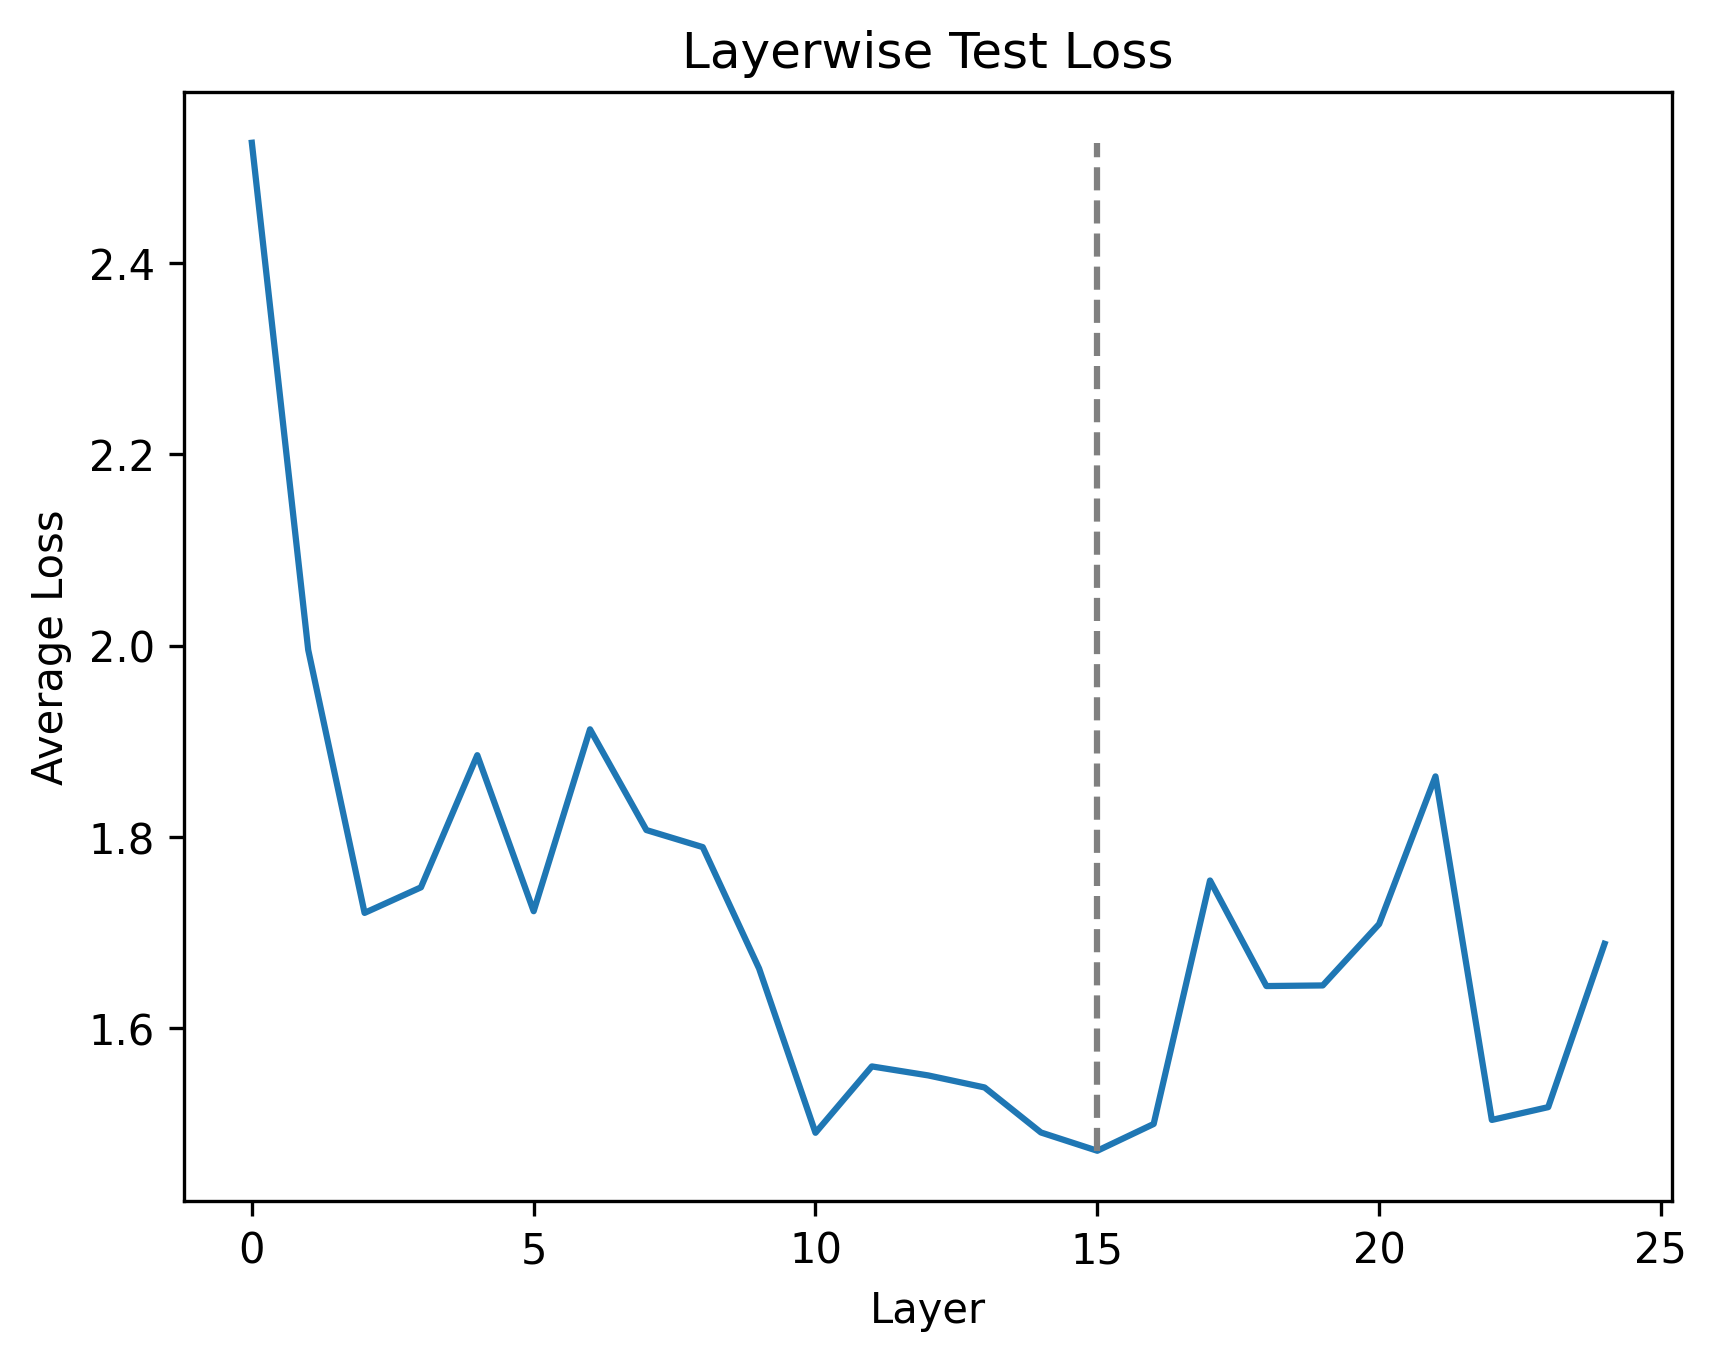

In [101]:
best_layer = np.argmin(layer_loss)
best = probes[best_layer]

plt.figure(dpi=300)
plt.title("Layerwise Test Loss")
plt.plot(layer_loss)
plt.vlines(best_layer, min(layer_loss), max(layer_loss), color="grey", linestyles="--")
plt.xlabel("Layer")
plt.ylabel("Average Loss")
plt.show()

In [ ]:
dataset = {}

for language in set(hf_dataset["test"]["language"]):
    hf_subset = hf_dataset["test"].filter(
        lambda example: example["language"] == language
    )

    tmp_dataset = DistanceProbeDataset(hf_subset, layer=best_layer)
    dataset[language] = DataLoader(
        tmp_dataset, batch_size=64, collate_fn=distance_collate
    )


Loading: 100%|██████████| 1/1 [00:00<00:00,  3.11it/s]


In [102]:
{str(l): len(loader.dataset) for l, loader in dataset.items()}

{'rust': 246,
 'python': 212,
 'cpp': 224,
 'c': 239,
 'javascript': 296,
 'php': 262,
 'haskell': 267,
 'go': 458,
 'java': 226}

In [ ]:
from collections import defaultdict

results = defaultdict(float)

for language, loader in dataset.items():
    for hidden, distance, mask in loader:
        hidden = hidden.to(device)
        distance = distance.to(device)
        mask = mask.to(device)

        with torch.no_grad():
            predicted_distance = best(hidden)

        results[language] += distance_loss(
            predicted_distance, distance, mask, reduce="sum"
        ).item()

    results[language] /= len(loader.dataset)

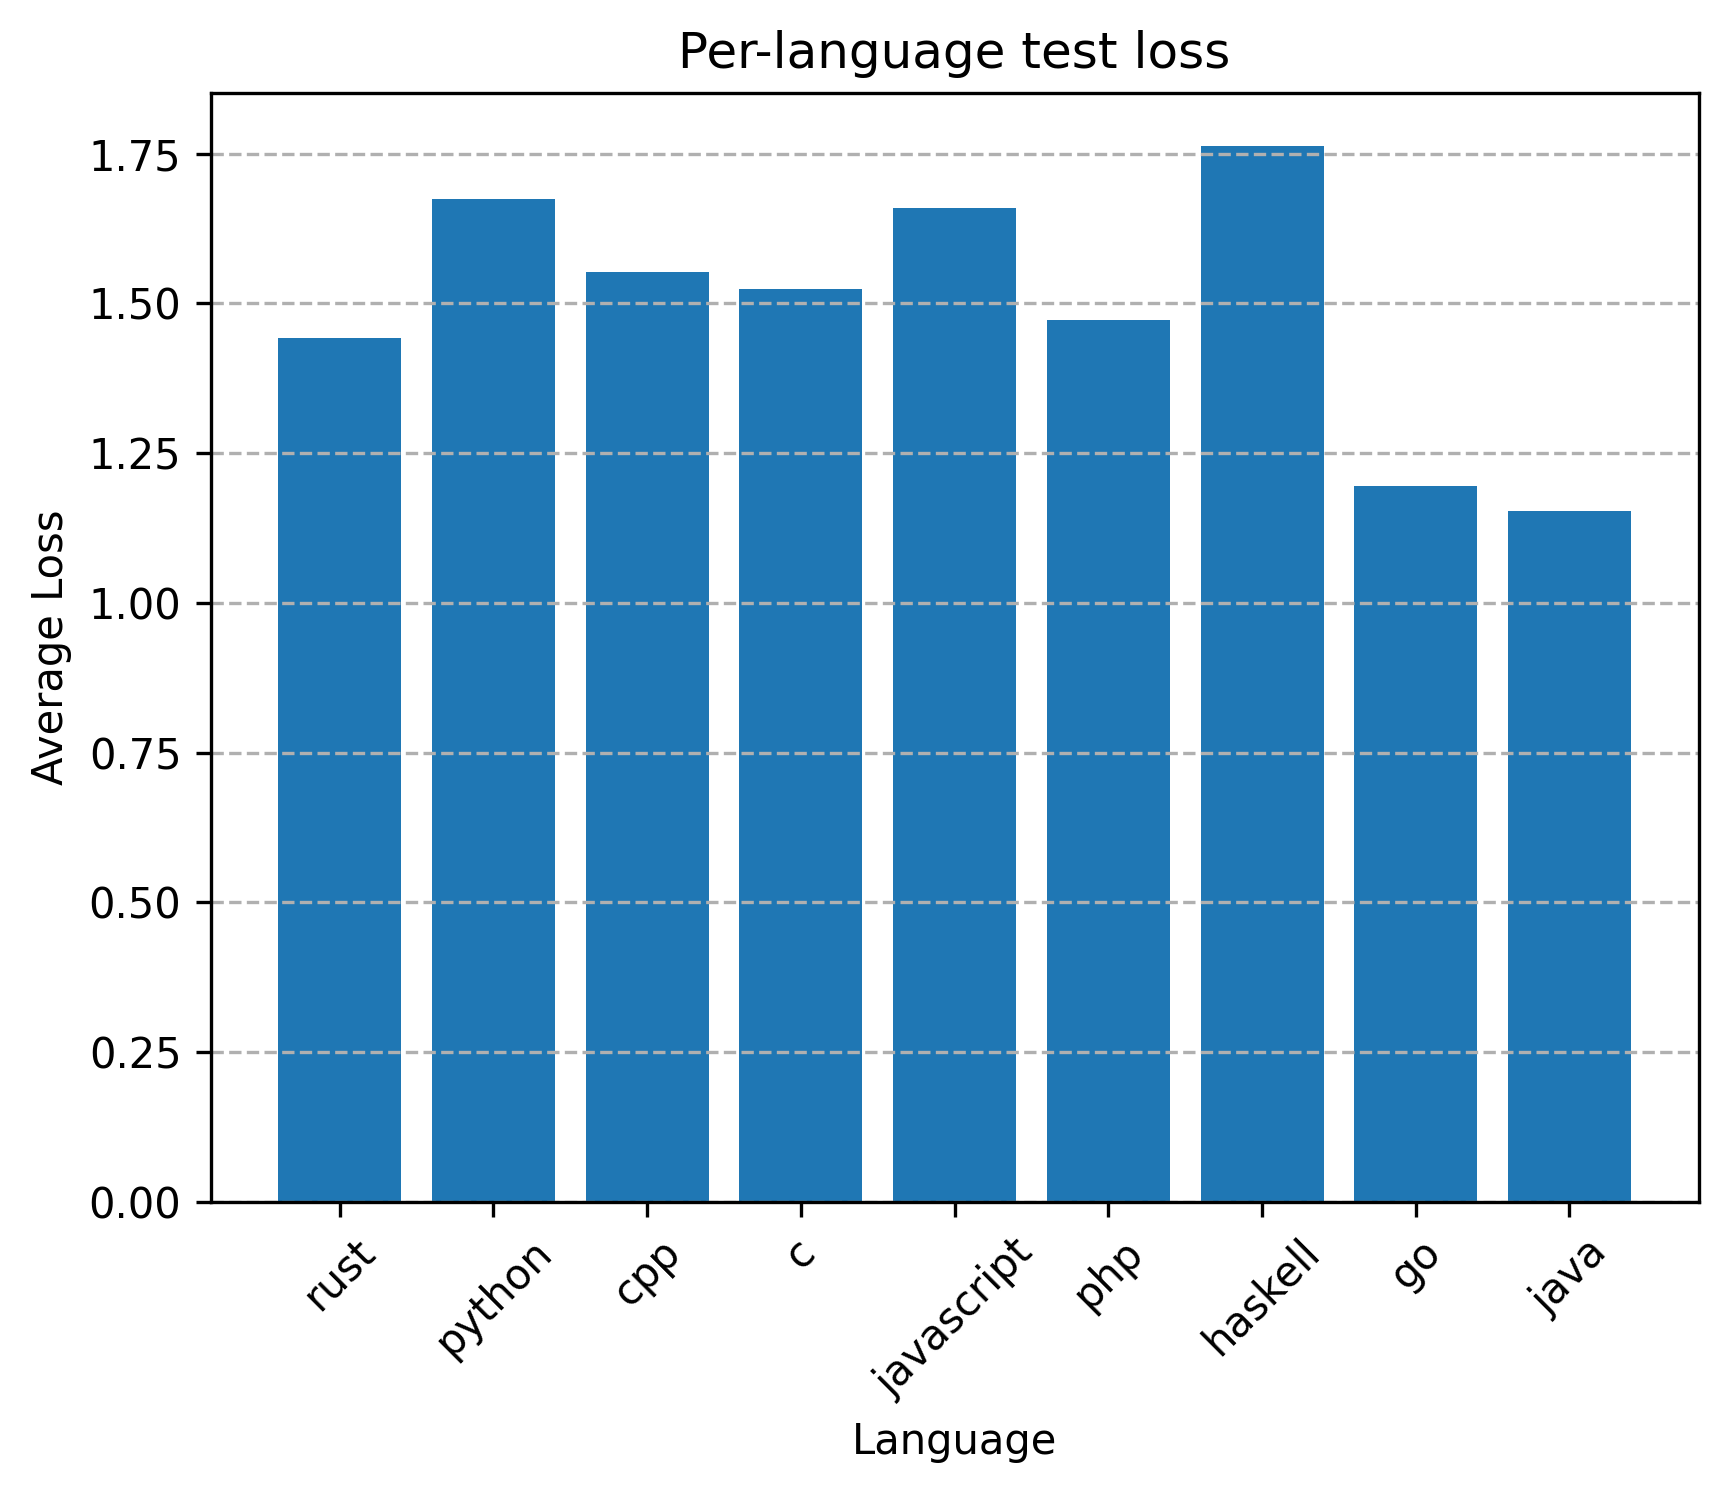

In [95]:
plt.figure(dpi=300)
plt.title("Per-language test loss")
plt.xticks(rotation=45)
plt.xlabel("Language")
plt.ylabel("Average Loss")
plt.grid(True, axis="y", which="both", linestyle="--")
plt.bar(results.keys(), results.values())
plt.show()